In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("insurance.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

Dataset dimensions: (1338, 7)

Column names:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1338.0,NaN,NaN,NaN,39.207025,14.04996,18.0,27.0,39.0,51.0,64.0
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1338.0,NaN,NaN,NaN,30.663397,6.098187,15.96,26.29625,30.4,34.69375,53.13
children,1338.0,NaN,NaN,NaN,1.094918,1.205493,0.0,0.0,1.0,2.0,5.0
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,1338.0,NaN,NaN,NaN,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


In [4]:
print("Missing values in each column:")
display(df.isnull().sum())

print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values in each column:


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Total missing values: 0
Duplicate rows: 1


In [5]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing exact duplicates:", df.shape)

Shape after removing exact duplicates: (1337, 7)


In [6]:
categorical_columns = ["sex", "smoker", "region"]

for col in categorical_columns:
    print(f"\nUnique values in {col}:")
    print(df[col].value_counts(dropna=False))
    


Unique values in sex:
sex
male      675
female    662
Name: count, dtype: int64

Unique values in smoker:
smoker
no     1063
yes     274
Name: count, dtype: int64

Unique values in region:
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64


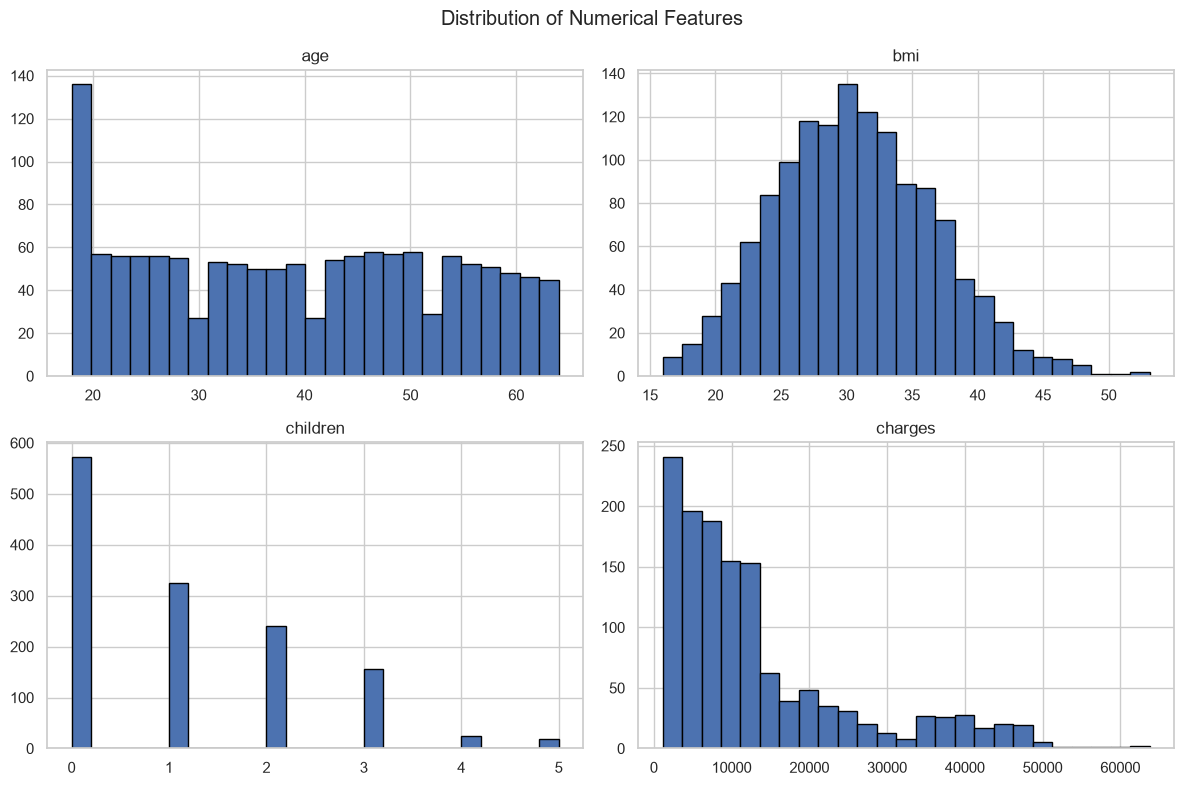

In [7]:
numeric_columns = ["age", "bmi", "children", "charges"]

df[numeric_columns].hist(
    figsize=(12, 8),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

In [8]:
skewness = df[numeric_columns].skew().sort_values(ascending=False)

print("Skewness of numerical columns:")
display(skewness.to_frame("Skewness"))

Skewness of numerical columns:


,Skewness
charges,1.515391
children,0.937421
bmi,0.283914
age,0.054781


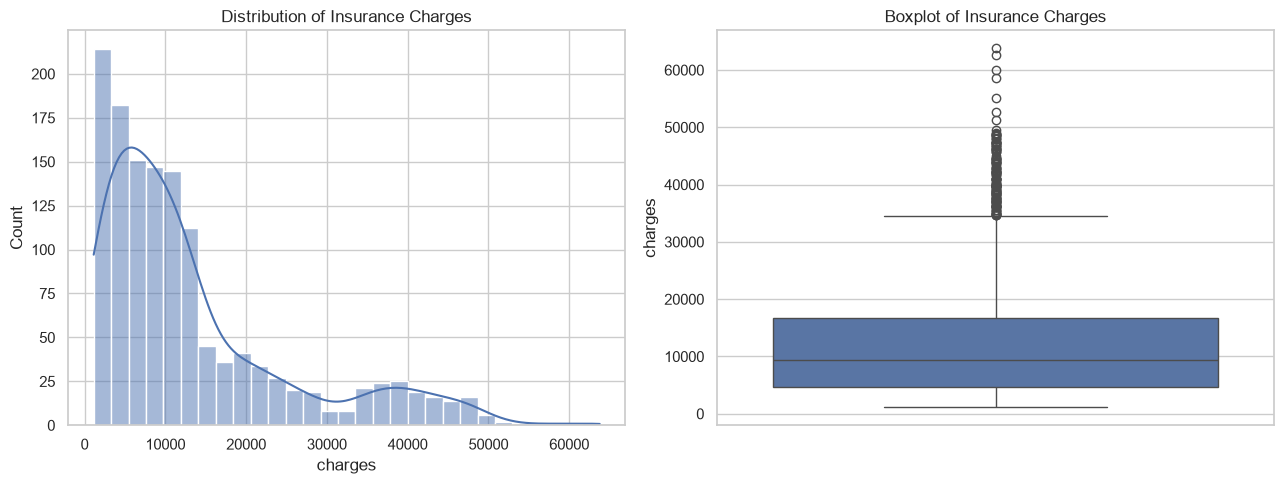

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df["charges"], kde=True, ax=axes[0])
axes[0].set_title("Distribution of Insurance Charges")

sns.boxplot(y=df["charges"], ax=axes[1])
axes[1].set_title("Boxplot of Insurance Charges")

plt.tight_layout()
plt.show()

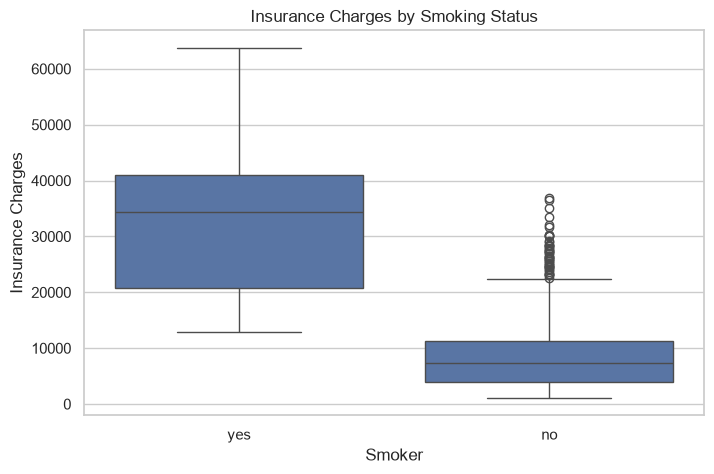

In [10]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="smoker", y="charges")

plt.title("Insurance Charges by Smoking Status")
plt.xlabel("Smoker")
plt.ylabel("Insurance Charges")
plt.show()

In [11]:
for col in ["age", "bmi", "children", "charges"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(f"{col}: {count} potential outliers")

age: 0 potential outliers
bmi: 9 potential outliers
children: 0 potential outliers
charges: 139 potential outliers


In [12]:
X = df.drop(columns=["charges"])
y = df["charges"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Feature shape: (1337, 6)
Target shape: (1337,)


,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest


0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 1069
Testing samples: 268


In [14]:
numeric_features = ["age", "bmi", "children"]
categorical_features = ["sex", "smoker", "region"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [15]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_processed_df = pd.DataFrame(
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed,
    columns=feature_names,
    index=X_train.index
)

display(X_train_processed_df.head())

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

,num__age,num__bmi,num__children,cat__sex_female,cat__sex_male,cat__smoker_no,cat__smoker_yes,cat__region_northeast,cat__region_northwest,cat__region_southeast,cat__region_southwest
1113,-1.157680,-0.996928,-0.907908,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0
967,-1.300619,-0.792762,0.766904,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0
598,0.914926,1.154664,0.766904,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
170,1.701087,1.806837,-0.907908,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0
275,0.557580,-0.651417,0.766904,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


Processed training shape: (1069, 11)
Processed testing shape: (268, 11)


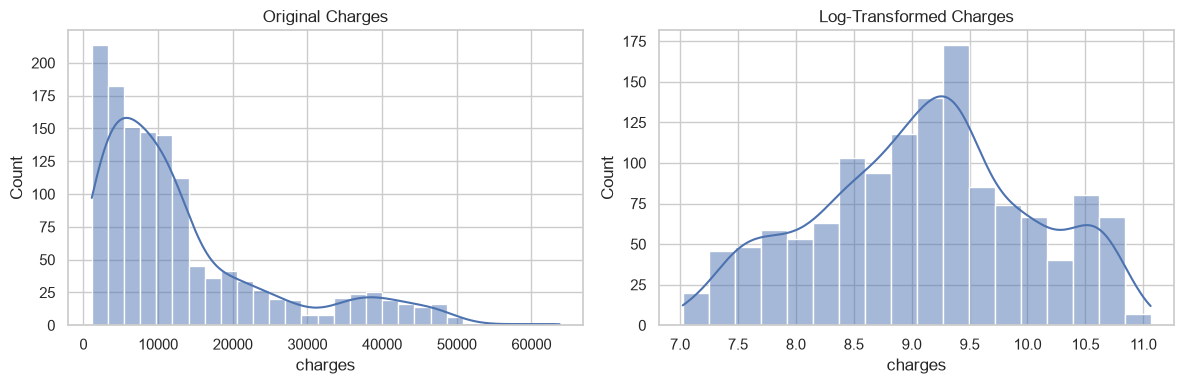

Original skewness: 1.515
Log-transformed skewness: -0.09


In [16]:
y_log = np.log1p(y)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(y, kde=True, ax=axes[0])
axes[0].set_title("Original Charges")

sns.histplot(y_log, kde=True, ax=axes[1])
axes[1].set_title("Log-Transformed Charges")

plt.tight_layout()
plt.show()

print("Original skewness:", round(y.skew(), 3))
print("Log-transformed skewness:", round(y_log.skew(), 3))